In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import xarray as xr
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import dask
from dask.diagnostics import ProgressBar

import sys

sys.path.append("../..")

from cordex2energy.conversion_energy.aggregate_data import (
    aggregate_data_per_country,
)
from cordex2energy.conversion_energy.hydropower import simple_hydropower_potential

from cordex2energy.utils.utils_xarray import sel_extent

from cordex2energy.utils.constants import EXTENT_CH, REFERENCE_PERIOD, EXTENT_BC, REGRIDDED_CHUNKS

sns.set_style("whitegrid", {"grid.color": ".93"})

In [3]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])

path_energy_ch = path_data_processed / "energy" / "ch"
path_energy_europe = path_data_processed / "energy" / "europe"

path_figs = Path(paths["path_figs"])

In [4]:
import os

os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

In [5]:
dask.config.set(num_workers=15, threads_per_worker=16)
dask.config.set(
    {
        "distributed.worker.memory.target": 0.7,  # Spill to disk at 70%
        "distributed.worker.memory.spill": 0.8,  # Start spilling at 80%
        "distributed.worker.memory.pause": 0.9,  # Pause worker at 90%
        "array.chunk-size": "512MiB",
        "logging.distributed": "error",  # Less verbose logs
    }
)

# Switzerland

In [ ]:
model_chains = [
    "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1",
    "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1",
]
climate_scenarios = ["rcp85"]

In [7]:
vars = ["pv", "wind_power", "water_availability"]
ds_var_yearly_ch = {var: [] for var in vars}
ds_var_ref_yearly_ch = {var: None for var in vars}

## PV

In [ ]:
path_pv = path_energy_ch / "pv"
data_var_pv = "tilt_35_azimuth_S"
ds_var_yearly_ch["pv"] = []
for climate_model_chain in model_chains:
    for climate_scenario in climate_scenarios:
        print(f"Processing {climate_model_chain} - {climate_scenario}...")
        climate_model_chain_scenario = climate_model_chain + "_" + climate_scenario
        path_model_chain = list(
            path_pv.glob(f"*/*{climate_model_chain}_{climate_scenario}*.zarr")
        )[0]
        ds_var_yearly_ch["pv"].append(
            xr.open_zarr(path_model_chain, chunks="auto")[data_var_pv].expand_dims(
                {"climate_model_chain_scenario": [climate_model_chain_scenario]}
            )
        )

ds_var_yearly_ch["pv"] = xr.concat(
    ds_var_yearly_ch["pv"], dim="climate_model_chain_scenario"
)

Processing CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1 - rcp85...
Processing MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1 - rcp85...
Processing MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1 - rcp85...


In [ ]:
with ProgressBar(dt=10):
    ds_var_yearly_ch["pv"] = (
        ds_var_yearly_ch["pv"]
        .mean(dim=["lat", "lon"])
        .resample(time="YE")
        .sum(dim="time")
        .compute()
    )

[########################################] | 100% Completed | 40.18 s


In [10]:
ds_var_yearly_ch

{'pv': <xarray.DataArray 'tilt_35_azimuth_S' (climate_model_chain_scenario: 3,
                                        time: 110)> Size: 3kB
 array([[388.75250721, 396.37203796, 412.46020618, 404.09140692,
         395.80322725, 416.36651908, 396.58648373, 410.3290243 ,
         423.90159614, 418.56295602, 419.89862136, 399.69821636,
         421.87502091, 416.99764447, 405.04105276, 407.80050442,
         414.43360912, 397.0172296 , 427.39997797, 434.84479221,
         407.50309848, 405.86193061, 413.79704905, 397.92366176,
         420.71887414, 412.35456515, 428.9634911 , 420.75609316,
         417.79001823, 419.96435007, 426.10752923, 429.57462068,
         413.43036534, 410.23190888, 434.21679186, 428.49707923,
         417.724552  , 417.34880948, 408.22924593, 395.10180258,
         415.54147625, 414.18176906, 400.25648608, 420.08690541,
         416.18232058, 411.01179169, 421.85049661, 415.78782908,
         419.54532732, 391.78390295, 428.83471686, 407.26767488,
         401.3

In [ ]:
ds_var_ref_yearly_ch["pv"] = (
    ds_var_yearly_ch["pv"]
    .sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))
    .mean(dim="time")
)

## Wind power

In [ ]:
path_wind_power = path_energy_ch / "wind_power"
data_var_wind_power = "E-92_2350"
ds_var_yearly_ch["wind_power"] = []
for climate_model_chain in model_chains:
    for climate_scenario in climate_scenarios:
        print(f"Processing {climate_model_chain} - {climate_scenario}...")
        climate_model_chain_scenario = climate_model_chain + "_" + climate_scenario
        path_model_chain = list(
            path_wind_power.glob(f"*{climate_model_chain}_{climate_scenario}*.zarr")
        )[0]
        ds_var_yearly_ch["wind_power"].append(
            xr.open_zarr(path_model_chain, chunks="auto")[
                data_var_wind_power
            ].expand_dims(
                {"climate_model_chain_scenario": [climate_model_chain_scenario]}
            )
        )

ds_var_yearly_ch["wind_power"] = xr.concat(
    ds_var_yearly_ch["wind_power"], dim="climate_model_chain_scenario"
)

Processing CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1 - rcp85...
Processing MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1 - rcp85...
Processing MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1 - rcp85...


In [ ]:
with ProgressBar(dt=10):
    ds_var_yearly_ch["wind_power"] = (
        ds_var_yearly_ch["wind_power"]
        .mean(dim=["lat", "lon"])
        .resample(time="YE")
        .sum(dim="time")
        .compute()
    )

[########################################] | 100% Completed | 20.03 s


In [ ]:
ds_var_ref_yearly_ch["wind_power"] = (
    ds_var_yearly_ch["wind_power"]
    .sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))
    .mean(dim="time")
)

## Water availability

In [ ]:
ds_var_yearly_ch["water_availability"] = []
for climate_model_chain in model_chains:
    for climate_scenario in climate_scenarios:
        print(f"Processing {climate_model_chain} - {climate_scenario}...")
        climate_model_chain_scenario = climate_model_chain + "_" + climate_scenario
        path_model_chain = list(
            path_data_processed.glob(
                f"cordex_processed/{climate_model_chain}_{climate_scenario}/**/day/mrro.zarr"
            )
        )[0]
        ds_var_yearly_ch["water_availability"].append(
            sel_extent(xr.open_zarr(path_model_chain, chunks="auto"), extent=EXTENT_CH)[
                "mrro"
            ].expand_dims(
                {"climate_model_chain_scenario": [climate_model_chain_scenario]}
            )
        )

ds_var_yearly_ch["water_availability"] = xr.concat(
    ds_var_yearly_ch["water_availability"], dim="climate_model_chain_scenario"
)

Processing CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1 - rcp85...
Processing MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1 - rcp85...
Processing MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1 - rcp85...


In [ ]:
with ProgressBar(dt=10):
    ds_var_yearly_ch["water_availability"] = (
        simple_hydropower_potential(
            ds_var_yearly_ch["water_availability"].chunk(REGRIDDED_CHUNKS),
            reference_period=["1991", "2020"],
            quantile_max=0.95,
        )
        .mean(dim=["lat", "lon"])
        .resample(time="YE")
        .sum(dim="time")
        .compute()
    )

[########################################] | 100% Completed | 70.25 s


In [ ]:
ds_var_ref_yearly_ch["water_availability"] = (
    ds_var_yearly_ch["water_availability"]
    .sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))
    .mean(dim="time")
)

## Plots

In [26]:
years = [2030, 2042, 2048]

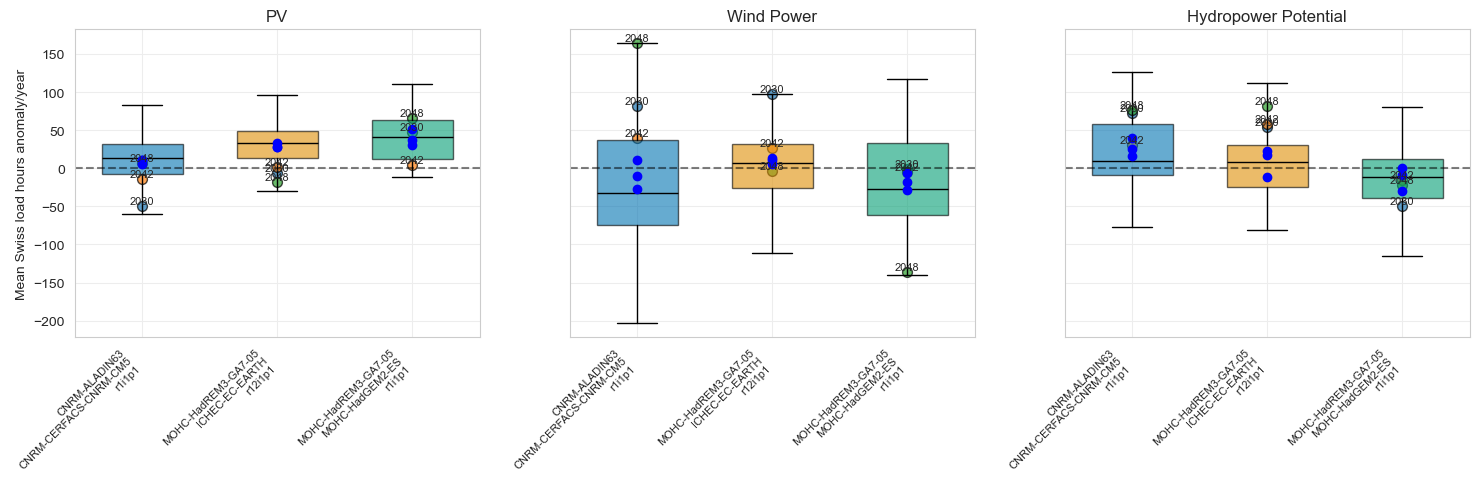

In [ ]:
# Calculate anomalies for period 2021-2060
anomalies = {}
for var in vars:
    anomalies[var] = (
        ds_var_yearly_ch[var].sel(time=slice("2021", "2060")) * 3
        - ds_var_ref_yearly_ch[var] * 3
    )

anomalies_decadal = {}
for var in vars:
    anomalies_decadal[var] = {}
    for year in [2030, 2040, 2050]:
        anomalies_decadal[var][year] = (
            ds_var_yearly_ch[var]
            .sel(time=slice(str(year - 9), str(year + 10)))
            .mean(dim="time")
            * 3
            - ds_var_ref_yearly_ch[var] * 3
        )

# Create figure with subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
palette = sns.color_palette("colorblind", n_colors=len(model_chains))

var_titles = {
    "pv": "PV",
    "wind_power": "Wind Power",
    "water_availability": "Hydropower Potential",
}

# Plot box plots for each variable
for i, var in enumerate(vars):
    data_list = []
    labels = []

    for j, climate_model_chain_scenario in enumerate(
        anomalies[var].climate_model_chain_scenario.values
    ):
        data = (
            anomalies[var]
            .sel(climate_model_chain_scenario=climate_model_chain_scenario)
            .values
        )
        data_list.append(data)
        labels.append(
            climate_model_chain_scenario.split("_rcp85")[0].replace("_", "\n")
        )

    bp = axes[i].boxplot(
        data_list,
        positions=range(len(data_list)),
        patch_artist=True,
        widths=0.6,
        showfliers=False,
    )

    # Color the box plots
    for patch, color in zip(bp["boxes"], palette):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)

    for element in ["whiskers", "fliers", "means", "medians", "caps"]:
        if element in bp:
            plt.setp(bp[element], color="black")

    # for year in years:
    #     year_data = []
    #     for j, climate_model_chain_scenario in enumerate(anomalies[var].climate_model_chain_scenario.values):
    #         data = anomalies[var].sel(climate_model_chain_scenario=climate_model_chain_scenario, time=str(year)).values
    #         year_data.append(data)
    #     axes[i].scatter(range(len(year_data)), year_data, color='red', marker='D', label=f'Year {year}' if j == 0 else "", zorder=3)
    #     axes[i].text(j, data, str(year), fontsize=6, ha='center', va='bottom')

    for decade in [2030, 2040, 2050]:
        decade_data = []
        for j, climate_model_chain_scenario in enumerate(
            anomalies[var].climate_model_chain_scenario.values
        ):
            data = (
                anomalies_decadal[var][decade]
                .sel(climate_model_chain_scenario=climate_model_chain_scenario)
                .values
            )
            decade_data.append(data)
        axes[i].scatter(
            range(len(decade_data)),
            decade_data,
            color="blue",
            marker="o",
            label=f"Decade {decade}" if j == 0 else "",
            zorder=3,
        )

    # Add scatter points for specific years
    for year in years:
        year_data = anomalies[var].sel(time=str(year)).values
        x_positions = range(len(year_data))
        axes[i].scatter(
            x_positions, year_data, alpha=0.7, s=50, edgecolors="black", linewidths=1
        )
        for x, y in zip(x_positions, year_data):
            axes[i].text(x, y + 0.01, str(year), fontsize=8, ha="center", va="bottom")

    axes[i].set_xticks(range(len(labels)))
    axes[i].set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    if i == 0:
        axes[i].set_ylabel("Mean Swiss load hours anomaly/year")
    axes[i].set_title(var_titles[var])
    axes[i].axhline(y=0, color="k", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(path_figs / "box_plots_anomaly_2021_2060.png", dpi=300, bbox_inches="tight")
plt.show()

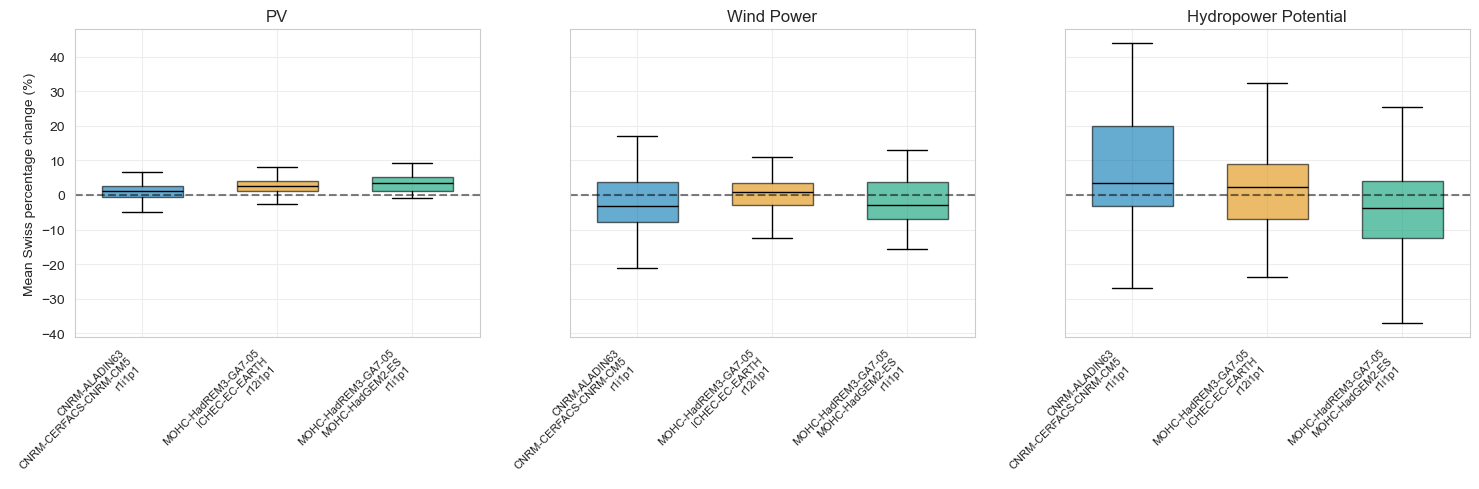

In [ ]:
# Calculate percentage changes for period 2021-2060
percentage_changes = {}
for var in vars:
    percentage_changes[var] = (
        (
            ds_var_yearly_ch[var].sel(time=slice("2021", "2060"))
            - ds_var_ref_yearly_ch[var]
        )
        / ds_var_ref_yearly_ch[var]
    ) * 100

# Create figure with subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
palette = sns.color_palette("colorblind", n_colors=len(model_chains))

var_titles = {
    "pv": "PV",
    "wind_power": "Wind Power",
    "water_availability": "Hydropower Potential",
}

# Plot box plots for each variable
for i, var in enumerate(vars):
    data_list = []
    labels = []

    for j, climate_model_chain_scenario in enumerate(
        percentage_changes[var].climate_model_chain_scenario.values
    ):
        data = (
            percentage_changes[var]
            .sel(climate_model_chain_scenario=climate_model_chain_scenario)
            .values
        )
        data_list.append(data)
        labels.append(
            climate_model_chain_scenario.split("_rcp85")[0].replace("_", "\n")
        )

    bp = axes[i].boxplot(
        data_list,
        positions=range(len(data_list)),
        patch_artist=True,
        widths=0.6,
        showfliers=False,
    )

    # Color the box plots
    for patch, color in zip(bp["boxes"], palette):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)

    for element in ["whiskers", "fliers", "means", "medians", "caps"]:
        if element in bp:
            plt.setp(bp[element], color="black")

    axes[i].set_xticks(range(len(labels)))
    axes[i].set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    if i == 0:
        axes[i].set_ylabel("Mean Swiss percentage change (%)")
    axes[i].set_title(var_titles[var])
    axes[i].axhline(y=0, color="k", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(
    path_figs / "box_plots_percentage_change_2021_2060.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## Find extreme years

In [ ]:
# Calculate combined metric for extremeness (sum of anomalies for all three variables)
combined_anomalies = {}

for climate_model_chain_scenario in anomalies["pv"].climate_model_chain_scenario.values:
    # Sum the anomalies across all three variables for each year
    combined = (
        anomalies["pv"].sel(climate_model_chain_scenario=climate_model_chain_scenario)
        + anomalies["wind_power"].sel(
            climate_model_chain_scenario=climate_model_chain_scenario
        )
        + anomalies["water_availability"].sel(
            climate_model_chain_scenario=climate_model_chain_scenario
        )
    )
    combined_anomalies[climate_model_chain_scenario] = combined

# Rank years by extremeness for each model
print("=" * 80)
print("YEARS RANKED BY EXTREMENESS (Most Extreme to Least Extreme)")
print("Based on sum of PV + Wind Power + Hydropower anomalies")
print("=" * 80)

for climate_model_chain_scenario in sorted(combined_anomalies.keys()):
    print(f"\n{climate_model_chain_scenario}:")
    print("-" * 60)

    combined = combined_anomalies[climate_model_chain_scenario]

    # Sort by absolute value to get most extreme (regardless of sign)
    sorted_indices = np.argsort(np.abs(combined.values))[::-1]

    print(f"{'Rank':<6} {'Year':<8} {'Combined Anomaly':<20} {'|Anomaly|':<15}")
    print("-" * 60)

    for rank, idx in enumerate(sorted_indices[:10], 1):  # Top 10 most extreme
        year = pd.Timestamp(combined.time.values[idx]).year
        value = combined.values[idx]
        abs_value = np.abs(value)
        print(f"{rank:<6} {year:<8} {value:>15.2f}     {abs_value:>15.2f}")

# Summary: Find the most extreme year across all models
print("\n" + "=" * 80)
print("MOST EXTREME YEARS (across all models)")
print("=" * 80)

all_years_extremeness = {}
for year_idx in range(len(combined_anomalies[list(combined_anomalies.keys())[0]])):
    year = pd.Timestamp(
        combined_anomalies[list(combined_anomalies.keys())[0]].time.values[year_idx]
    ).year

    # Average absolute anomaly across all models
    avg_abs_anomaly = np.mean(
        [
            np.abs(combined_anomalies[model].values[year_idx])
            for model in combined_anomalies.keys()
        ]
    )

    all_years_extremeness[year] = avg_abs_anomaly

# Sort years by average extremeness
sorted_years = sorted(all_years_extremeness.items(), key=lambda x: x[1], reverse=True)

print(f"\n{'Rank':<6} {'Year':<8} {'Avg |Anomaly| across models':<30}")
print("-" * 60)
for rank, (year, extremeness) in enumerate(sorted_years[:10], 1):
    print(f"{rank:<6} {year:<8} {extremeness:>25.2f}")

YEARS RANKED BY EXTREMENESS (Most Extreme to Least Extreme)
Based on sum of PV + Wind Power + Hydropower anomalies

CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85:
------------------------------------------------------------
Rank   Year     Combined Anomaly     |Anomaly|      
------------------------------------------------------------
1      2045               96.00               96.00
2      2040               86.70               86.70
3      2025              -84.11               84.11
4      2048               82.25               82.25
5      2021              -54.51               54.51
6      2026               40.80               40.80
7      2046               40.46               40.46
8      2052              -40.17               40.17
9      2032              -37.09               37.09
10     2030               34.59               34.59

MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1_rcp85:
------------------------------------------------------------
Rank   Year     Combined An

# Europe

In [8]:
model_chains = [
    "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1",
]
climate_scenarios = ["rcp26"]

In [9]:
vars = ["pv", "wind_power", "water_availability"]
vars = ["pv", "wind_power"]
ds_var_yearly_europe = {var: [] for var in vars}
ds_var_ref_yearly_europe = {var: None for var in vars}

## PV

In [10]:
path_pv = path_energy_europe / "pv"
data_var_pv = "tilt_35_azimuth_S"
ds_var_yearly_europe["pv"] = []
for climate_model_chain in model_chains:
    for climate_scenario in climate_scenarios:
        print(f"Processing {climate_model_chain} - {climate_scenario}...")
        climate_model_chain_scenario = climate_model_chain + "_" + climate_scenario
        path_model_chain = list(
            path_pv.glob(f"*/*{climate_model_chain}_{climate_scenario}*.nc")
        )[0]
        ds_var_yearly_europe["pv"].append(
            xr.open_dataset(path_model_chain, chunks="auto")[data_var_pv].expand_dims(
                {"climate_model_chain_scenario": [climate_model_chain_scenario]}
            )
        )

ds_var_yearly_europe["pv"] = xr.concat(
    ds_var_yearly_europe["pv"], dim="climate_model_chain_scenario"
)

Processing CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1 - rcp26...
Processing MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1 - rcp26...


In [11]:
with ProgressBar(dt=5):
    ds_var_yearly_europe["pv"] = (
        ds_var_yearly_europe["pv"]
        .mean(dim=["country"])
        .resample(time="YE")
        .sum(dim="time")
        .compute()
    )

[########################################] | 100% Completed | 15.02 s


In [12]:
ds_var_ref_yearly_europe["pv"] = (
    ds_var_yearly_europe["pv"]
    .sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))
    .mean(dim="time")
)

## Wind power

In [13]:
path_wind_power = path_energy_europe / "wind_power"
data_var_wind_power = "E-126_7580"
ds_var_yearly_europe["wind_power"] = []
for climate_model_chain in model_chains:
    for climate_scenario in climate_scenarios:
        print(f"Processing {climate_model_chain} - {climate_scenario}...")
        climate_model_chain_scenario = climate_model_chain + "_" + climate_scenario
        path_model_chain = list(
            path_wind_power.glob(f"*/*{climate_model_chain}_{climate_scenario}*.nc")
        )[0]
        ds_var_yearly_europe["wind_power"].append(
            xr.open_dataset(path_model_chain, chunks="auto")[
                data_var_wind_power
            ].expand_dims(
                {"climate_model_chain_scenario": [climate_model_chain_scenario]}
            )
        )

ds_var_yearly_europe["wind_power"] = xr.concat(
    ds_var_yearly_europe["wind_power"], dim="climate_model_chain_scenario"
)

Processing CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1 - rcp26...
Processing MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1 - rcp26...


In [15]:
with ProgressBar(dt=10):
    ds_var_yearly_europe["wind_power"] = (
        ds_var_yearly_europe["wind_power"]
        .mean(dim=["country"])
        .resample(time="YE")
        .sum(dim="time")
        .compute()
    )

[########################################] | 100% Completed | 20.01 s


In [16]:
ds_var_ref_yearly_europe["wind_power"] = (
    ds_var_yearly_europe["wind_power"]
    .sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))
    .mean(dim="time")
)

## Water availability

In [ ]:
ds_var_yearly_ch["water_availability"] = []
for climate_model_chain in model_chains:
    for climate_scenario in climate_scenarios:
        print(f"Processing {climate_model_chain} - {climate_scenario}...")
        climate_model_chain_scenario = climate_model_chain + "_" + climate_scenario
        path_model_chain = list(
            path_data_processed.glob(
                f"cordex_processed/{climate_model_chain}_{climate_scenario}/**/day/mrro.zarr"
            )
        )[0]
        ds_var_yearly_ch["water_availability"].append(
            sel_extent(xr.open_zarr(path_model_chain, chunks="auto"), extent=EXTENT_CH)[
                "mrro"
            ].expand_dims(
                {"climate_model_chain_scenario": [climate_model_chain_scenario]}
            )
        )

ds_var_yearly_ch["water_availability"] = xr.concat(
    ds_var_yearly_ch["water_availability"], dim="climate_model_chain_scenario"
)

Processing CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1 - rcp85...
Processing MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1 - rcp85...
Processing MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1 - rcp85...


In [ ]:
with ProgressBar(dt=10):
    ds_var_yearly_ch["water_availability"] = (
        simple_hydropower_potential(
            ds_var_yearly_ch["water_availability"].chunk(REGRIDDED_CHUNKS),
            reference_period=["1991", "2020"],
            quantile_max=0.95,
        )
        .mean(dim=["lat", "lon"])
        .resample(time="YE")
        .sum(dim="time")
        .compute()
    )

[########################################] | 100% Completed | 70.25 s


In [ ]:
ds_var_ref_yearly_ch["water_availability"] = (
    ds_var_yearly_ch["water_availability"]
    .sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))
    .mean(dim="time")
)

## Plots

In [17]:
years = [2030, 2039, 2050]

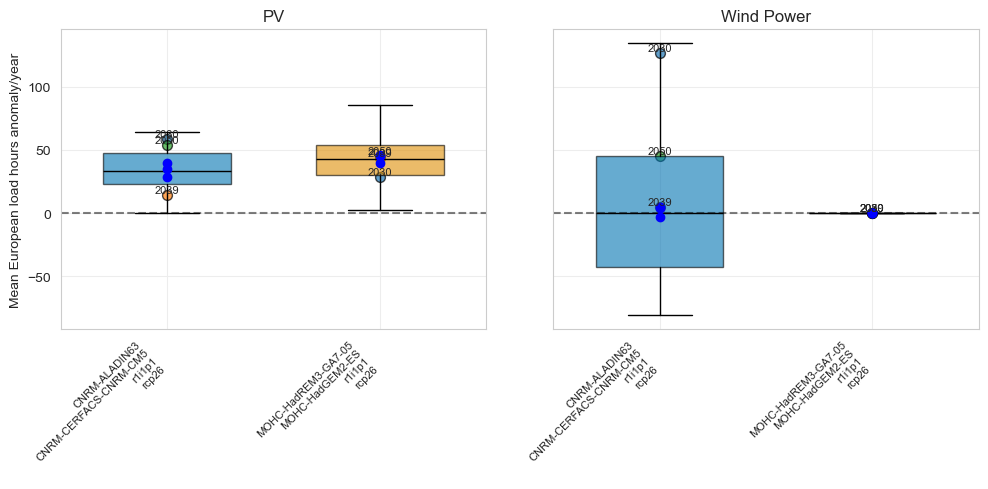

In [24]:
# Calculate anomalies for period 2021-2060
anomalies = {}
for var in vars:
    anomalies[var] = (
        ds_var_yearly_europe[var].sel(time=slice("2021", "2060")) * 3
        - ds_var_ref_yearly_europe[var] * 3
    )

anomalies_decadal = {}
for var in vars:
    anomalies_decadal[var] = {}
    for year in [2030, 2040, 2050]:
        anomalies_decadal[var][year] = (
            ds_var_yearly_europe[var]
            .sel(time=slice(str(year - 9), str(year + 10)))
            .mean(dim="time")
            * 3
            - ds_var_ref_yearly_europe[var] * 3
        )

# Create figure with subplots
fig, axes = plt.subplots(1, len(vars), figsize=(10, 5), sharey=True)
palette = sns.color_palette("colorblind", n_colors=len(model_chains))

var_titles = {
    "pv": "PV",
    "wind_power": "Wind Power",
    "water_availability": "Hydropower Potential",
}

# Plot box plots for each variable
for i, var in enumerate(vars):
    data_list = []
    labels = []

    for j, climate_model_chain_scenario in enumerate(
        anomalies[var].climate_model_chain_scenario.values
    ):
        data = (
            anomalies[var]
            .sel(climate_model_chain_scenario=climate_model_chain_scenario)
            .values
        )
        data_list.append(data)
        labels.append(
            climate_model_chain_scenario.split("_rcp85")[0].replace("_", "\n")
        )

    bp = axes[i].boxplot(
        data_list,
        positions=range(len(data_list)),
        patch_artist=True,
        widths=0.6,
        showfliers=False,
    )

    # Color the box plots
    for patch, color in zip(bp["boxes"], palette):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)

    for element in ["whiskers", "fliers", "means", "medians", "caps"]:
        if element in bp:
            plt.setp(bp[element], color="black")

    # for year in years:
    #     year_data = []
    #     for j, climate_model_chain_scenario in enumerate(anomalies[var].climate_model_chain_scenario.values):
    #         data = anomalies[var].sel(climate_model_chain_scenario=climate_model_chain_scenario, time=str(year)).values
    #         year_data.append(data)
    #     axes[i].scatter(range(len(year_data)), year_data, color='red', marker='D', label=f'Year {year}' if j == 0 else "", zorder=3)
    #     axes[i].text(j, data, str(year), fontsize=6, ha='center', va='bottom')

    for decade in [2030, 2040, 2050]:
        decade_data = []
        for j, climate_model_chain_scenario in enumerate(
            anomalies[var].climate_model_chain_scenario.values
        ):
            data = (
                anomalies_decadal[var][decade]
                .sel(climate_model_chain_scenario=climate_model_chain_scenario)
                .values
            )
            decade_data.append(data)
        axes[i].scatter(
            range(len(decade_data)),
            decade_data,
            color="blue",
            marker="o",
            label=f"Decade {decade}" if j == 0 else "",
            zorder=3,
        )

    # Add scatter points for specific years
    for year in years:
        year_data = anomalies[var].sel(time=str(year)).values
        x_positions = range(len(year_data))
        axes[i].scatter(
            x_positions, year_data, alpha=0.7, s=50, edgecolors="black", linewidths=1
        )
        for x, y in zip(x_positions, year_data):
            axes[i].text(x, y + 0.01, str(year), fontsize=8, ha="center", va="bottom")

    axes[i].set_xticks(range(len(labels)))
    axes[i].set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    if i == 0:
        axes[i].set_ylabel("Mean European load hours anomaly/year")
    axes[i].set_title(var_titles[var])
    axes[i].axhline(y=0, color="k", linestyle="--", alpha=0.5)

plt.tight_layout()
# plt.savefig(path_figs / "box_plots_anomaly_2021_2060.png", dpi=300, bbox_inches="tight")
plt.show()

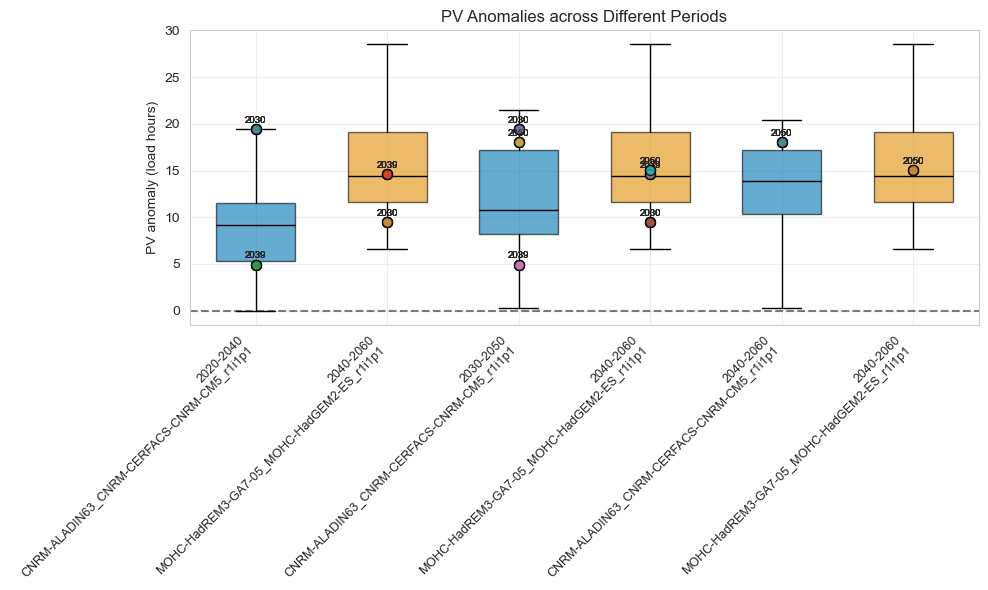

In [22]:
# Calculate anomalies for different periods
periods = [(2020, 2040), (2030, 2050), (2040, 2060)]
anomalies_periods = {}

for var in vars:
    anomalies_periods[var] = {}
    for start_year, end_year in periods:
        period_label = f"{start_year}-{end_year}"
        anomalies_periods[var][period_label] = (
            ds_var_yearly_europe[var].sel(time=slice(str(start_year), str(end_year)))
            - ds_var_ref_yearly_europe[var]
        )

# Create boxplot for PV across different periods
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
palette = sns.color_palette("colorblind", n_colors=len(model_chains))

data_list = []
labels = []
colors = []

for period_label in [f"{start}-{end}" for start, end in periods]:
    for j, climate_model_chain_scenario in enumerate(
        anomalies_periods["pv"][period_label].climate_model_chain_scenario.values
    ):
        data = (
            anomalies_periods["pv"][period_label]
            .sel(climate_model_chain_scenario=climate_model_chain_scenario)
            .values
        )
        data_list.append(data)
        model_name = climate_model_chain_scenario.split("_rcp26")[0]
        labels.append(f"{period_label}\n{model_name}")
        colors.append(palette[j])
        # Add scatter points for specific years that fall within each period
        for period_idx, (start_year, end_year) in enumerate(periods):
            period_label = f"{start_year}-{end_year}"
            # Get the position indices for this period's boxes
            period_positions = [period_idx * len(model_chains) + j for j in range(len(model_chains))]

            for year in years:
                if start_year <= year <= end_year:
                    year_data = []
                    for climate_model_chain_scenario in anomalies_periods["pv"][period_label].climate_model_chain_scenario.values:
                        data = anomalies_periods["pv"][period_label].sel(
                            climate_model_chain_scenario=climate_model_chain_scenario,
                            time=str(year)
                        ).values
                        year_data.append(data)

                    # Plot scatter points at the corresponding box positions
                    for pos, y_val in zip(period_positions, year_data):
                        ax.scatter(pos, y_val, alpha=0.7, s=50, edgecolors="black", linewidths=1, zorder=3)
                        ax.text(pos, y_val + 0.5, str(year), fontsize=7, ha='center', va='bottom')

bp = ax.boxplot(
    data_list,
    positions=range(len(data_list)),
    patch_artist=True,
    widths=0.6,
    showfliers=False,
)

# Color the box plots
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

for element in ["whiskers", "fliers", "means", "medians", "caps"]:
    if element in bp:
        plt.setp(bp[element], color="black")

ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("PV anomaly (load hours)")
ax.set_title("PV Anomalies across Different Periods")
ax.axhline(y=0, color="k", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [19]:
# Calculate percentage changes for period 2021-2060
percentage_changes = {}
for var in vars:
    percentage_changes[var] = (
        (
            ds_var_yearly_ch[var].sel(time=slice("2021", "2060"))
            - ds_var_ref_yearly_ch[var]
        )
        / ds_var_ref_yearly_ch[var]
    ) * 100

# Create figure with subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
palette = sns.color_palette("colorblind", n_colors=len(model_chains))

var_titles = {
    "pv": "PV",
    "wind_power": "Wind Power",
    "water_availability": "Hydropower Potential",
}

# Plot box plots for each variable
for i, var in enumerate(vars):
    data_list = []
    labels = []

    for j, climate_model_chain_scenario in enumerate(
        percentage_changes[var].climate_model_chain_scenario.values
    ):
        data = (
            percentage_changes[var]
            .sel(climate_model_chain_scenario=climate_model_chain_scenario)
            .values
        )
        data_list.append(data)
        labels.append(
            climate_model_chain_scenario.split("_rcp85")[0].replace("_", "\n")
        )

    bp = axes[i].boxplot(
        data_list,
        positions=range(len(data_list)),
        patch_artist=True,
        widths=0.6,
        showfliers=False,
    )

    # Color the box plots
    for patch, color in zip(bp["boxes"], palette):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)

    for element in ["whiskers", "fliers", "means", "medians", "caps"]:
        if element in bp:
            plt.setp(bp[element], color="black")

    axes[i].set_xticks(range(len(labels)))
    axes[i].set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    if i == 0:
        axes[i].set_ylabel("Mean Swiss percentage change (%)")
    axes[i].set_title(var_titles[var])
    axes[i].axhline(y=0, color="k", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(
    path_figs / "box_plots_percentage_change_2021_2060.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

NameError: name 'ds_var_yearly_ch' is not defined